# 07 · Effect on the training pool

**Question:** if the reclassified segments replaced the ATL08 · PhoREAL (today) segments as model training data, how would the training pool
change: its height distribution by land cover, the share of short vegetation, and the share of segments whose height changes
by more than 2 m?

This uses the matched segments from notebook 04 (G-LiHT tiles) and notebook 01 (Seward). The step through the height-to-biomass
models and `mapBoreal` (plan §4.6) runs in the R pipeline and is not done here: the new segments carry the same RH columns
(canopy-only, ATL08 style) plus GEDI-style RH over ground + canopy photons (`rh*_gedi`), which match the definitions the GEDI
biomass models expect.

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. "v007" is the NASA data release; every version below uses release 007. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds of one config version (`config/atl03_reclass_v0.N.yaml`). |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments: a name says whose photon classes, then who cut them into 30 m segments and computed the heights**
| | binned by SlideRule PhoREAL | binned by our code (`segment_metrics`) |
|---|---|---|
| **ATL08 v007 photon classes** | **ATL08 · PhoREAL (today)**: what our training files contain today | **ATL08 · our binning (control)**: same classes, our binning; any difference from "today" is binning, not classification |
| **reclassified photon classes** | (not made) | **reclassified v0.N**: the candidate product, config v0.N |

Comparing **today** with **reclassified v0.N** is the result that matters; the **control** shows how much of that difference
comes from binning alone. Earlier notebooks and LOG entries called these "current v7 30 m", "ATL08 classes → our 30 m (check)"
and "reclassified photons → our 30 m (new)".

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.6 40e8f82a4112 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.6


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "0cecd4e",
 "git_dirty_lib_or_config": true,
 "config_version": "0.6",
 "config_sha1": "40e8f82a4112",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-18T12:26:33"
}


## Load the matched segments

**Input:** the three versions of 30 m segments for the G-LiHT tiles (notebook 04) and the Seward transects (notebook 01);
only segments that have a **ATL08 · PhoREAL (today)** match. Land cover from the ATL08 `segment_landcover` (ESA WorldCover codes).
`change` = new − current `h_canopy`.

In [2]:
segs = pd.concat([gpd.read_parquet(f) for f in sorted((RUN / "segments").glob("tile_*_segments.parquet"))], ignore_index=True)
sew = pd.concat([gpd.read_parquet(f) for f in sorted((RUN / "seward").glob("*_segments.parquet"))], ignore_index=True).assign(region="Seward")
s = pd.concat([segs, sew], ignore_index=True)
s = s[s.h_canopy_phoreal.notna()]
WC = {10: "tree", 20: "shrub", 30: "grass", 40: "crop", 50: "built", 60: "bare/sparse", 70: "snow/ice", 80: "water",
      90: "wetland", 95: "mangrove", 100: "moss/lichen"}
s["landcover"] = s.get("segment_landcover", pd.Series(np.nan, index=s.index)).map(WC).fillna("unknown")
s["change"] = s.h_canopy - s.h_canopy_phoreal
print(len(s), "matched segments")

34725 matched segments


In [3]:
summ = s.groupby(["region", "landcover"]).agg(n=("change", "size"),
                                             current_median=("h_canopy_phoreal", "median"), new_median=("h_canopy", "median"),
                                             current_p95=("h_canopy_phoreal", lambda v: v.quantile(0.95)), new_p95=("h_canopy", lambda v: v.quantile(0.95)),
                                             short_veg_flag=("short_veg_flag", "mean"),
                                             changed_gt_2m=("change", lambda v: (v.abs() > 2).mean())).round(2)
summ[summ.n >= 30]

n  current_median  new_median  current_p95  new_p95  \
region   landcover                                                              
Interior bare/sparse    184            5.61        0.00    16.840000     9.18   
         grass         3260            0.92        0.00     8.090000     5.62   
         shrub         2690            0.86        0.00     5.320000     5.52   
         unknown      14891            3.71        3.82    16.150000    20.15   
         water          288            0.18        0.00     6.900000     2.44   
Kenai    bare/sparse     72            4.81        0.00    18.750000    13.13   
         built          132            4.59        3.29    18.450001    11.30   
         grass          635            5.12        2.10    20.540001    18.08   
         shrub          140            2.55        1.36    20.889999    15.44   
         snow/ice       259            2.83        0.00    29.520000     8.68   
         unknown       9596            4.41        0.77    19.840000    20.43   
         water          184            0.20        0.00     4.910000     0.00   
         wetland        740            0.39        0.00     8.130000     5.25   
Seward   grass          427            1.27        0.00     5.750000     3.99   
         shrub          253            2.90        1.62     5.280000     4.55   
         unknown        967            3.05        0.00     8.380000     5.41   

                      short_veg_flag  changed_gt_2m  
region   landcover                                   
Interior bare/sparse            0.40           0.45  
         grass                  0.45           0.16  
         shrub                  0.46           0.12  
         unknown                0.17           0.23  
         water                  0.74           0.04  
Kenai    bare/sparse            0.42           0.44  
         built                  0.10           0.06  
         grass                  0.28           0.28  
         shrub                  0.29           0.25  
         snow/ice               0.61           0.42  
         unknown                0.30           0.18  
         water                  0.70           0.01  
         wetland                0.56           0.07  
Seward   grass                  0.45           0.12  
         shrub                  0.35           0.23  
         unknown                0.25           0.21

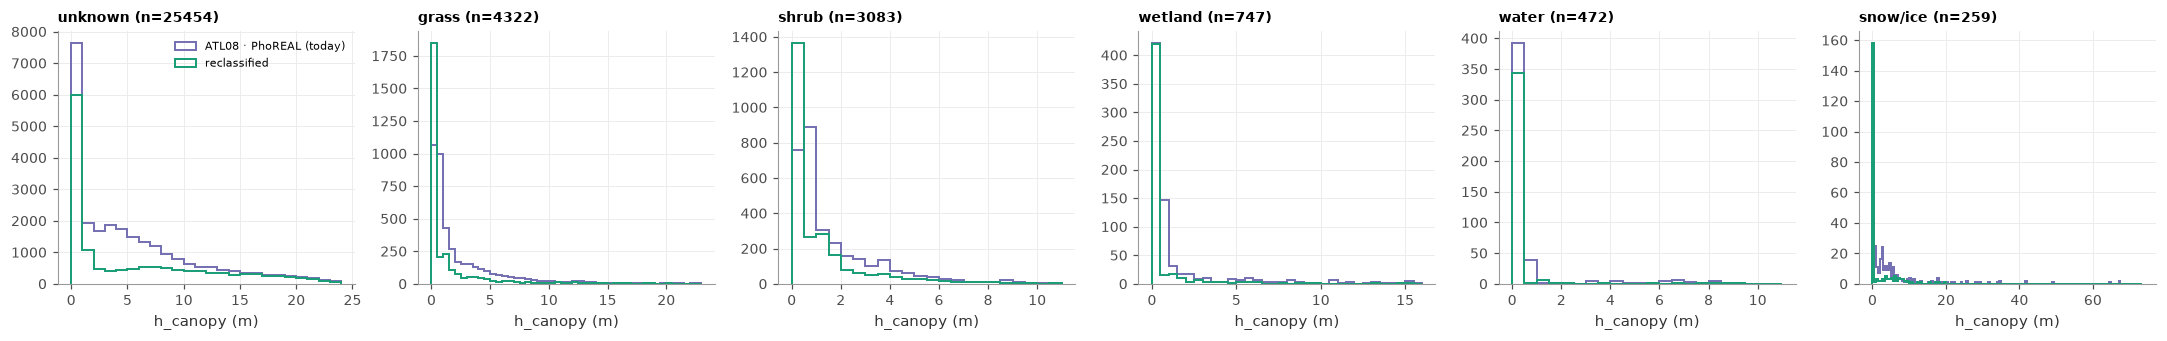

In [4]:
lcs = [lc for lc, n in s.landcover.value_counts().items() if n >= 100][:6]
fig, axes = plt.subplots(1, len(lcs), figsize=(3.3 * len(lcs), 3.2), squeeze=False)
for ax, lc in zip(axes[0], lcs):
    g = s[s.landcover == lc]
    bins = np.arange(0, max(5, np.nanpercentile(g.h_canopy_phoreal, 99)) + 1, 0.5 if g.h_canopy_phoreal.median() < 3 else 1)
    ax.hist(g.h_canopy_phoreal, bins=bins, histtype="step", lw=1.3, color=val.SCHEME_COLORS[val.LABEL_CURRENT], label=val.LABEL_CURRENT)
    ax.hist(g.h_canopy, bins=bins, histtype="step", lw=1.3, color=val.SCHEME_COLORS[val.LABEL_NEW], label=val.LABEL_NEW)
    ax.set_title(f"{lc} (n={len(g)})", loc="left", fontsize=9); ax.set_xlabel("h_canopy (m)")
axes[0, 0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "07_training_pool_by_landcover.png", dpi=150)

## Results (config v0.6, 18 October 2026)

34,725 segments matched to today's training segments (G-LiHT tiles and Seward).
- **Short vegetation moves to 0 m:** median height over grass and shrub in the Interior falls from 0.9 m to 0 m, over Seward
  grass from 1.3 m to 0 m, and over bare / sparse ground from 4.8–5.6 m to 0 m; 25–46 % of grass, shrub and tundra segments are
  0 m (vegetation would have been seen and was not), against the false shrub heights of today's pool.
- **Forest keeps its height:** in the unlabelled (mostly forest) class the Interior median stays at 3.7–3.8 m and the 95th
  percentile rises from 16.2 to 20.2 m (less tall-forest underestimation).
- **How much the pool moves:** 12–28 % of grass, shrub and forest segments change by more than 2 m; 42–45 % of bare and snow /
  ice segments (their false heights are removed).
- The step through the height-to-biomass models and `mapBoreal` runs in the R pipeline (plan §4.6) and is the next step with
  the v0.6 segments.